<a href="https://colab.research.google.com/github/rozmar/Analyzing-Open-Neuroscience-Data-SZTE-2027/blob/main/Modul%202/03_Transcriptomics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **DRAFT – instructor notes (delete before class)**
> * Rough timing (after the 15 min talk): 1. the matrix 10 min · 2. normalization 15 min · 3. marker genes 15 min ·
>   4. a map of the cells 10 min (cut first if short on time) · 5. genes and electrophysiology 15 min ·
>   6. mouse and human 10 min.
> * Loading `mouse_expression.h5ad` takes ~15 s and ~1 GB of memory (fine on Colab). After section 2 everything runs on
>   the small `mouse_expression_selected.parquet` table; the full matrix is only needed again for the `expression()`
>   function and the homework.
> * Needs `scikit-learn` (preinstalled on Colab; added to `pyproject.toml` for local installs).
> * Fix-me cells will be added later.

# Transcriptomics

Two weeks ago we looked at the **shape** of the neurons, last week at how they **fire**. Today: which **genes** they
use. This is the third modality of Patch-seq, and the one that gave the cells their type labels.

At the end of the recording, the content of the cell (with its RNA) was sucked into the patch pipette. The RNA was
copied into DNA, amplified, and **sequenced**: cut into millions of short pieces (*reads*), each read was matched to
the gene it came from, and the reads were counted. The result, for every cell, is a list of numbers: how many reads
each gene got. A gene with many reads is strongly **expressed**: the cell makes a lot of its RNA, and probably of its
protein too.

**Today we will:**
1. open the expression matrix of all mouse cells (an **AnnData** file),
2. turn read counts into comparable expression levels (**normalization**),
3. check that the transcriptome knows the cell types (**marker genes**),
4. draw a map of all cells from their genes (**PCA**),
5. look for the ion channel genes behind the electrical differences of last week,
6. and compare mouse and human.

**From the bootcamp you will need:** functions, `numpy` arrays and boolean masks, `pandas` (`merge`, `groupby`,
`crosstab`, `sort_values`), and `matplotlib` (`imshow`, subplots).

What the words and columns mean is explained in the
[course glossary](https://github.com/rozmar/Analyzing-Open-Neuroscience-Data-SZTE-2027/blob/main/Modul%202/Glossary.md#transcriptomics)
(`Glossary.md` next to this notebook).

## 0. Setup

As in the previous weeks: on Colab this downloads the course repository and builds the course data (about a minute).
We also need **anndata**, the package for reading single-cell expression files.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO = "/content/Analyzing-Open-Neuroscience-Data-SZTE-2027"
    if not os.path.exists(REPO):
        !git clone --depth 1 https://github.com/rozmar/Analyzing-Open-Neuroscience-Data-SZTE-2027.git {REPO}
    os.chdir(REPO + "/Modul 2")
    %pip install -q anndata

DATA = Path("data")
if not (DATA / "cells.csv").exists():
    print("Building the course data, this takes about a minute...")
    %run 00_Build_Course_Data.ipynb
print("Course data is in:", DATA.resolve())

Course data is in: /tmp/claude-0/-home-claude/b4f81d30-26af-541c-bc7d-7da69c1e5da0/scratchpad/buildtest/Modul 2/data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata
import warnings

# genes with no reads in any cell give "constant input" warnings when correlated; they are simply skipped
warnings.filterwarnings("ignore", message="An input array is constant")

COLORS = {"Pvalb": "#D93137", "Sst": "#FF9900", "Sst Chodl": "#B1B10C", "Vip": "#B864CC",
          "Lamp5": "#DA808C", "Sncg": "#6B8E23", "Lamp5/Pax6/Other": "#DA808C"}
subclasses = ["Lamp5", "Sncg", "Vip", "Sst", "Sst Chodl", "Pvalb"]

cells = pd.read_csv(DATA / "cells.csv", low_memory=False)
cells_by_id = cells.set_index("cell_id")

## 1. The expression matrix

The expression data of the mouse cells is one big table: one row per **cell**, one column per **gene**. It is stored
in an **AnnData** file (`.h5ad`), the standard format for single-cell data. An AnnData object keeps three things
together:

* `adata.X`: the numbers, cells × genes,
* `adata.obs`: a table about the cells (*observations*), one row per cell,
* `adata.var`: a table about the genes (*variables*), one row per gene.

Loading takes a few seconds.

In [3]:
adata = anndata.read_h5ad(DATA / "mouse_expression.h5ad")
adata

AnnData object with n_obs × n_vars = 4435 × 45768
    obs: 'library_size'
    uns: 'description', 'values'
    layers: None (.X)

In [4]:
print(adata.uns["description"])
print()
print("cells:", adata.obs_names[:3].tolist(), "...")
print("genes:", adata.var_names[:5].tolist(), "...")
adata.obs.head()

Gouwens et al. 2020 mouse Patch-seq. X = raw read counts (int32). CPM = X / obs['library_size'] * 1e6; the course uses log2(CPM + 1).

cells: ['mouse_601506507', 'mouse_601790961', 'mouse_601803754'] ...
genes: ['0610005C13Rik', '0610006L08Rik', '0610007P14Rik', '0610009B22Rik', '0610009E02Rik'] ...


,library_size
cell_id,
mouse_601506507,985775.0
mouse_601790961,252106.0
mouse_601803754,588583.0
mouse_601808698,532056.0
mouse_601810307,308507.0


The rows are named by our `cell_id`, the columns by the **gene symbol**. Mouse gene symbols are written with a capital
first letter (`Pvalb`), human ones in all capitals (`PVALB`).

How big is this table?

In [5]:
n_cells, n_genes = adata.shape
print(n_cells, "cells x", n_genes, "genes =", n_cells * n_genes, "numbers")
print("but only", adata.X.nnz, "of them are not zero:", round(100 * adata.X.nnz / (n_cells * n_genes), 1), "%")

4435 cells x 45768 genes = 202981080 numbers
but only 39453161 of them are not zero: 19.4 %


Most genes are not used by a given cell, so most of the numbers are zero. Instead of storing all of them, `adata.X`
is a **sparse matrix**: it only remembers the non-zero values and where they are. That saves a lot of memory, but it
cannot be printed or plotted directly; `.toarray()` turns a (small!) piece of it into a normal `numpy` array.

Let's look at one cell: the Vip cell of the last two weeks.

In [6]:
example_id = "mouse_601506507"
some_genes = ["Snap25", "Gad1", "Slc17a7", "Pvalb", "Sst", "Vip", "Lamp5"]

one_cell = adata[example_id, some_genes].X.toarray()[0]
pd.Series(one_cell, index=some_genes)

Snap25      1352
Gad1        5863
Slc17a7        0
Pvalb          0
Sst            0
Vip        16783
Lamp5          0
dtype: int32

`adata[rows, columns]` works like `.loc` in pandas: here one cell and seven genes. The numbers are **read counts**.
*Snap25* (a gene of all neurons) and *Gad1* (the enzyme that makes GABA) have many reads; *Slc17a7*, the marker of
excitatory neurons, has few. And *Vip*? (Many more genes are explained in the glossary.)

**Question.** Which subclass would you guess for this cell from these numbers alone? Check `cells_by_id.loc[example_id]`.

Two numbers describe the quality of each cell's data: the **library size** (the total number of reads of the cell,
in `adata.obs`) and the number of **genes detected** (genes with at least one read).

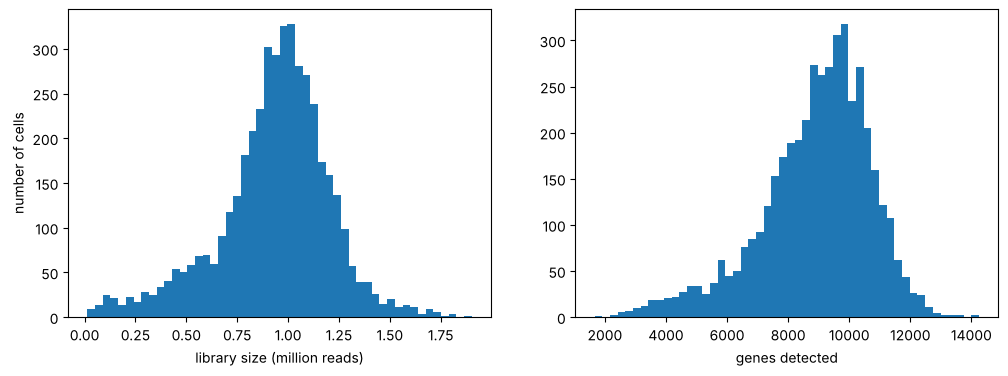

In [7]:
library_size = adata.obs["library_size"]
genes_detected = np.asarray((adata.X > 0).sum(axis=1)).ravel()   # count the non-zero genes in each row

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(library_size / 1e6, bins=50)
axes[0].set_xlabel("library size (million reads)")
axes[0].set_ylabel("number of cells")
axes[1].hist(genes_detected, bins=50)
axes[1].set_xlabel("genes detected")
plt.show()

**Questions.** About how many reads does a typical cell have? How many of the ~46,000 genes does a typical neuron use?
Some cells have far fewer reads than the others. Why could that happen in a Patch-seq experiment?

## 2. From counts to expression levels

Can we compare the counts of two cells directly? Let's take a few genes for all cells and put them in a `pandas`
table.

In [8]:
my_genes = ["Snap25", "Gad1", "Pvalb", "Sst", "Vip", "Kcnc2"]
counts = pd.DataFrame(adata[:, my_genes].X.toarray(), index=adata.obs_names, columns=my_genes)
counts.head()

,Snap25,Gad1,Pvalb,Sst,Vip,Kcnc2
cell_id,,,,,,
mouse_601506507,1352,5863,0,0,16783,1740
mouse_601790961,1281,1207,0,1627,0,384
mouse_601803754,929,871,0,2936,0,385
mouse_601808698,656,434,0,531,0,110
mouse_601810307,605,479,0,185,0,136


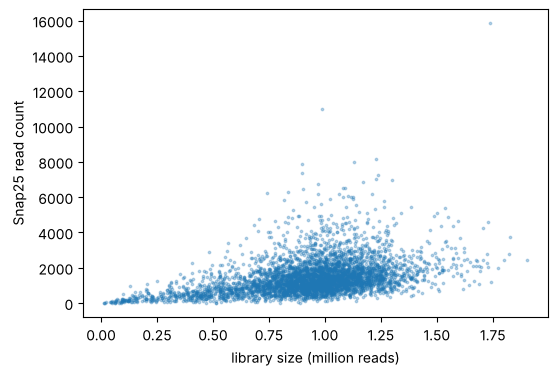

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(library_size / 1e6, counts["Snap25"], s=3, alpha=0.3)
ax.set_xlabel("library size (million reads)")
ax.set_ylabel("Snap25 read count")
plt.show()

*Snap25* is used by every neuron at a similar level, yet its count goes up with the library size: a cell that got
twice as many reads in total gets about twice as many *Snap25* reads too. The counts mix two things: how much the cell
uses a gene, and how deeply it happened to be sequenced.

The fix is to divide by the library size. **CPM**, counts per million, is the number of reads a gene would have if
the cell had exactly one million reads:

$$\text{CPM} = \frac{\text{count}}{\text{library size}} \times 10^6$$

`counts.div(library_size, axis=0)` divides every **row** (`axis=0`: along the cells) by that cell's library size.

In [10]:
cpm = counts.div(library_size, axis=0) * 1e6
cpm.head().round(1)

,Snap25,Gad1,Pvalb,Sst,Vip,Kcnc2
cell_id,,,,,,
mouse_601506507,1371.5,5947.6,0.0,0.0,17025.2,1765.1
mouse_601790961,5081.2,4787.7,0.0,6453.6,0.0,1523.2
mouse_601803754,1578.4,1479.8,0.0,4988.3,0.0,654.1
mouse_601808698,1233.0,815.7,0.0,998.0,0.0,206.7
mouse_601810307,1961.1,1552.6,0.0,599.7,0.0,440.8


There is one more step. Look at how the values of a marker gene are distributed:

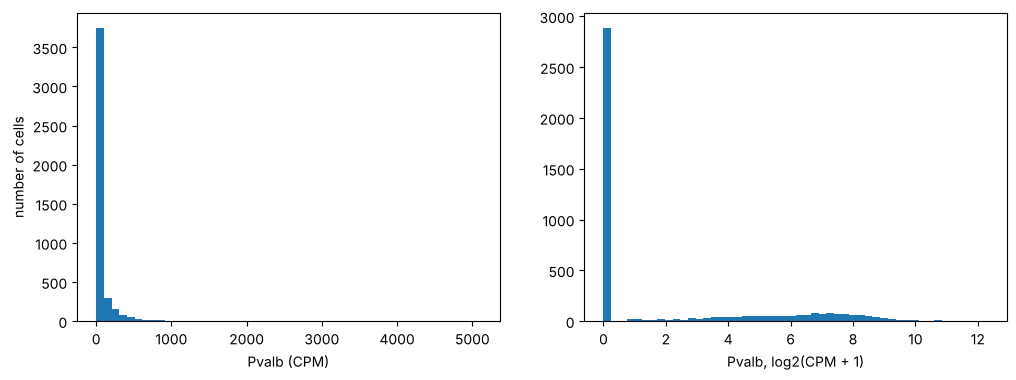

In [11]:
log_expr = np.log2(cpm + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cpm["Pvalb"], bins=50)
axes[0].set_xlabel("Pvalb (CPM)")
axes[0].set_ylabel("number of cells")
axes[1].hist(log_expr["Pvalb"], bins=50)
axes[1].set_xlabel("Pvalb, log2(CPM + 1)")
plt.show()

In CPM, a few cells with huge values squeeze everything else to the left. On a **logarithmic** scale every doubling
is one step, so a cell with 100 CPM and one with 10,000 CPM can be shown together: next to the many cells without any
*Pvalb* (the bar at 0), the cells that do use it spread out over a broad range. We add 1 before the logarithm because log(0) does not exist; this way 0 CPM stays 0.

**log2(CPM + 1)** is the standard scale for gene expression. The course data has it precomputed, for the 184 genes we
selected (all voltage-gated ion channels and 40 marker genes), in `mouse_expression_selected.parquet`. Did we get the
same numbers?

In [12]:
expr = pd.read_parquet(DATA / "mouse_expression_selected.parquet")
print(expr.shape)

difference = (log_expr - expr[my_genes]).abs().max()
print(difference)
assert difference.max() < 1e-3, "our normalization differs from the course table"

(4435, 184)
Snap25    4.766033e-07
Gad1      4.767652e-07
Pvalb     4.742114e-07
Sst       4.767974e-07
Vip       4.767636e-07
Kcnc2     4.766865e-07
dtype: float64


It's the same. From now on we use `expr`: a normal `pandas` table, small and fast. For any other gene we can go back
to the full matrix; let's wrap the steps of this section in a function:

In [13]:
def expression(gene):
    """log2(CPM + 1) of one gene in every mouse cell, computed from the full matrix."""
    gene_counts = adata[:, gene].X.toarray().ravel()
    cpm = gene_counts / library_size.values * 1e6
    return pd.Series(np.log2(cpm + 1), index=adata.obs_names, name=gene)

gfap = expression("Gfap")
print(round(100 * (gfap > 0).mean()), "% of the cells have Gfap reads")

24 % of the cells have Gfap reads


*Gfap* is a gene of **astrocytes**, not of neurons. Still, some cells have reads of it: in Patch-seq the pipette can
pick up a little RNA from the neighbouring cells, too (*contamination*). One more reason why Patch-seq data is noisier
than data from sorted, dissociated cells.

## 3. Marker genes: does the transcriptome know the cell type?

The `subclass` of each cell in `cells.csv` came from its transcriptome: the cell was compared with a reference
"atlas" of thousands of sequenced cells and got the label of the most similar type. A few **marker genes**, used
mainly by one subclass, should show that. Let's compute the average expression of some markers in each subclass.

In [14]:
subclass = cells_by_id.loc[expr.index, "subclass"]          # one label per row of expr, in the same order
markers = ["Snap25", "Gad1", "Slc17a7", "Lhx6", "Pvalb", "Sst", "Chodl",
           "Adarb2", "Vip", "Sncg", "Lamp5", "Ndnf"]

mean_expr = expr[markers].groupby(subclass).mean().loc[subclasses]
mean_expr.round(1)

,Snap25,Gad1,Slc17a7,Lhx6,Pvalb,Sst,Chodl,Adarb2,Vip,Sncg,Lamp5,Ndnf
subclass,,,,,,,,,,,,
Lamp5,10.8,10.5,1.9,0.4,0.8,0.4,0.0,10.9,0.3,0.2,8.4,4.4
Sncg,10.2,9.3,1.8,0.1,0.6,0.4,0.0,13.4,7.3,3.8,1.1,0.1
Vip,10.1,9.7,1.9,0.0,0.6,0.3,0.1,12.0,12.1,0.1,1.1,0.0
Sst,10.5,8.7,1.5,5.1,1.2,10.5,0.0,0.8,0.1,0.1,0.7,0.4
Sst Chodl,9.2,10.4,1.7,5.4,0.4,11.9,7.9,1.1,0.0,0.2,0.4,0.2
Pvalb,10.4,9.7,1.7,4.9,7.0,1.3,0.0,0.9,0.1,0.1,0.7,0.1


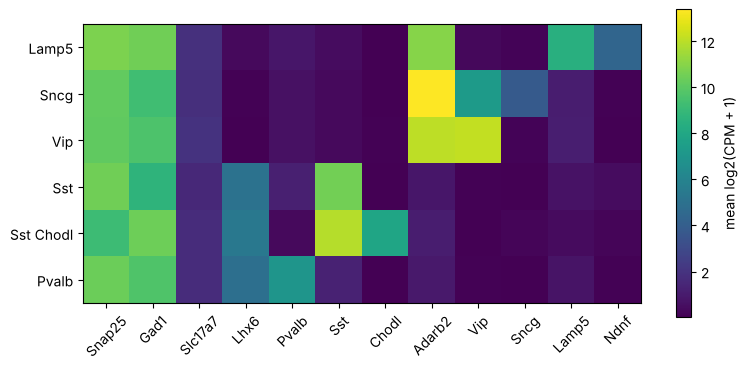

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(mean_expr, cmap="viridis")
ax.set_xticks(range(len(markers)))
ax.set_xticklabels(markers, rotation=45)
ax.set_yticks(range(len(subclasses)))
ax.set_yticklabels(subclasses)
fig.colorbar(image, label="mean log2(CPM + 1)")
plt.show()

**Questions.**
* Which genes are high in **every** subclass? Why? (All our cells are GABAergic neurons.)
* Find the marker of each subclass. Which subclass has **two** markers? (*Sst Chodl* cells are long-range projecting
  GABAergic cells.)
* *Lhx6* and *Adarb2* split the subclasses into two groups. These are the two embryonic birthplaces of cortical
  interneurons, the MGE and the CGE (see the `class` column of `cells.csv`).
* *Slc17a7* should be zero in GABAergic cells. Why isn't it?

The averages hide how individual cells behave. Here is *Pvalb* in the Pvalb cells and in all the others:

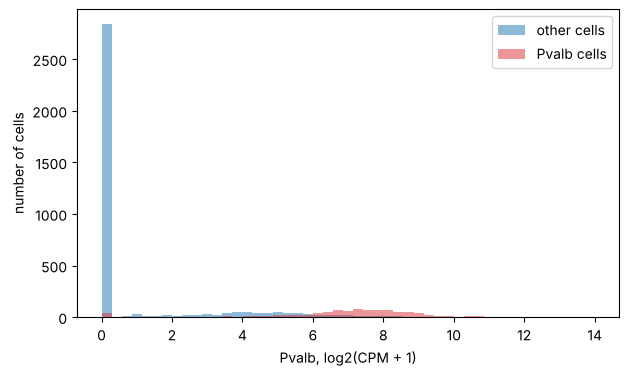

44 of 884 Pvalb cells have no Pvalb reads at all


In [16]:
is_pvalb = subclass == "Pvalb"

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 14, 50)
ax.hist(expr.loc[~is_pvalb, "Pvalb"], bins=bins, alpha=0.5, label="other cells")
ax.hist(expr.loc[is_pvalb, "Pvalb"], bins=bins, alpha=0.5, color=COLORS["Pvalb"], label="Pvalb cells")
ax.set_xlabel("Pvalb, log2(CPM + 1)")
ax.set_ylabel("number of cells")
ax.legend()
plt.show()

print((expr.loc[is_pvalb, "Pvalb"] == 0).sum(), "of", is_pvalb.sum(), "Pvalb cells have no Pvalb reads at all")

Some Pvalb cells have no *Pvalb* reads. A missing gene in a single cell is common (*dropout*): with so little RNA,
some molecules are simply lost. This is why the type is assigned from hundreds of genes together, not from one marker.

### 3.1 How were the cells found?

To patch a given cell type, the Allen Institute used **transgenic mice**: in an `Sst-IRES-Cre` mouse, the cells that
express *Sst* also make a red fluorescent protein, so they can be seen and targeted under the microscope. The line is
in the `genotype` column. Does the line predict the subclass that the transcriptome found later?

In [17]:
genotype = cells_by_id.loc[expr.index, "genotype"]
driver = genotype.str.split("-").str[0]        # "Sst-IRES-Cre/wt;Ai14..." -> "Sst"
print(driver.value_counts().head(8))

table = pd.crosstab(driver, subclass)
table.loc[["Pvalb", "Sst", "Vip", "Sncg", "Ndnf", "Nos1", "Chrna2"], subclasses]

genotype
Sst        1133
Vip         503
Pvalb       450
Ndnf        231
Gad2        220
Htr3a       215
Sncg        213
Slc32a1     158
Name: count, dtype: int64


subclass,Lamp5,Sncg,Vip,Sst,Sst Chodl,Pvalb
genotype,,,,,,
Pvalb,2,0,0,14,0,425
Sst,2,0,0,1003,27,101
Vip,4,26,450,6,1,10
Sncg,8,191,13,0,1,0
Ndnf,209,2,4,11,2,2
Nos1,17,0,2,17,90,3
Chrna2,3,11,27,84,0,19


`pd.crosstab` counts how many cells have each combination of the two labels.

**Questions.** Which lines are the most specific? Which line catches cells of another subclass, too? *Ndnf*, *Nos1*
and *Chrna2* are not subclass markers; which cells do they label? (Hint: look back at the heatmap, and at the
`t_type` of those cells.)

### 3.2 The three cells of the course

The Pvalb, Sst and Vip cells whose shape and firing we have seen in the last two weeks:

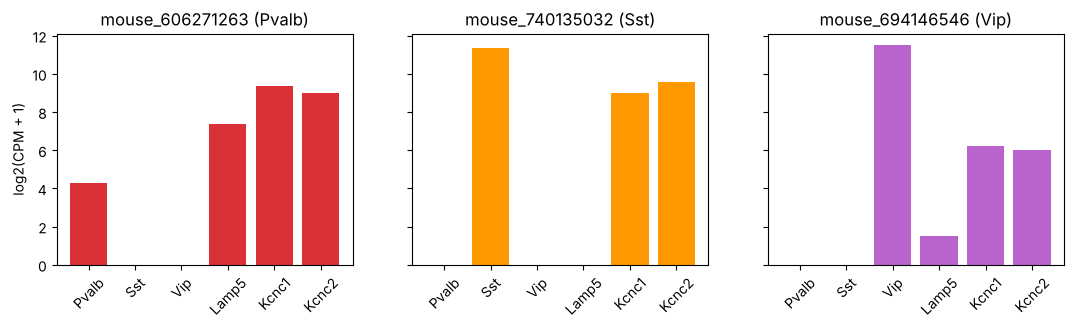

In [18]:
gallery = {"mouse_606271263": "Pvalb", "mouse_740135032": "Sst", "mouse_694146546": "Vip"}
gallery_markers = ["Pvalb", "Sst", "Vip", "Lamp5", "Kcnc1", "Kcnc2"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, (cell_id, name) in zip(axes, gallery.items()):
    ax.bar(gallery_markers, expr.loc[cell_id, gallery_markers], color=COLORS[name])
    ax.set_title(f"{cell_id} ({name})")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("log2(CPM + 1)")
plt.show()

**Question.** Does each cell express its own marker? Anything surprising? (Single cells are noisy: compare with the
averages in the heatmap.)

## 4. A map of all cells

So far we chose the genes to look at. Can the cells sort themselves out, from all 184 genes at once? Every cell is a
point in a 184-dimensional space, which we cannot draw. **Principal component analysis (PCA)** finds the directions in
which the cells differ the most, and lets us look at the cells along the two most important ones: a flat "shadow" of
the cloud that keeps as much of the differences as possible.

PCA is in the **scikit-learn** package (`sklearn`), the standard Python toolbox for machine learning.

share of the differences kept by PC1 and PC2: [0.16 0.08]


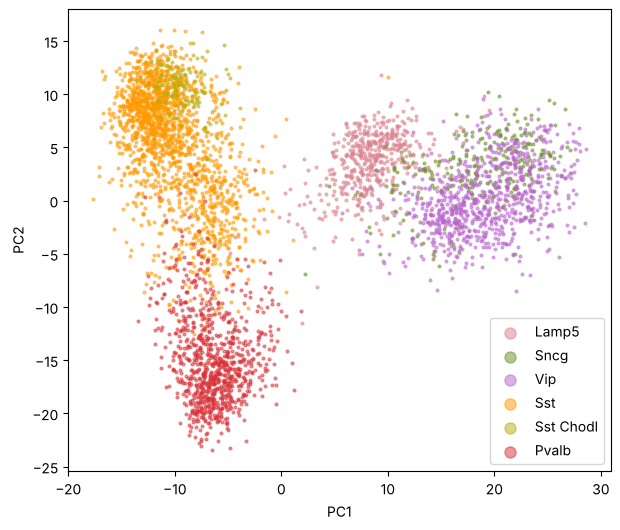

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(expr)              # one row per cell, two columns: PC1 and PC2
print("share of the differences kept by PC1 and PC2:", pca.explained_variance_ratio_.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
for sc in subclasses:
    is_sc = (subclass == sc).values
    ax.scatter(pcs[is_sc, 0], pcs[is_sc, 1], s=4, alpha=0.5, color=COLORS[sc], label=sc)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=4)
plt.show()

PCA was not told the subclasses, yet they form separate groups. Which genes make PC1? Each principal component is a
weighted sum of the genes; `pca.components_` holds the weights. Genes with large positive or negative weights pull
the cells to the right or to the left.

In [20]:
pc1_weights = pd.Series(pca.components_[0], index=expr.columns).sort_values()
pd.concat([pc1_weights.head(5), pc1_weights.tail(5)]).round(2)     # the 5 most negative and the 5 most positive

Sst      -0.30
Lhx6     -0.18
Kcnc2    -0.14
Calb1    -0.13
Kcnt1    -0.12
Tac2      0.19
Prox1     0.21
Kit       0.25
Vip       0.33
Adarb2    0.41
dtype: float32

**Questions.**
* PC1 separates two big groups. Compare the genes with the heatmap: which groups are they? Check by coloring the
  points by the `class` column instead of the subclass.
* Make the same plot from the **ion channel genes only** (`expr[channel_genes]`, see the next section). Do the
  subclasses still separate? What does that suggest about their electrical behaviour?

## 5. Genes and electrophysiology

Last week the Pvalb cells had the narrowest action potentials. A spike is short if the cell repolarizes fast, which
needs fast potassium channels. The fastest ones are the **Kv3** channels, coded by the genes *Kcnc1*–*Kcnc4*. Do
Pvalb cells express more of them?

`genes_selected.csv` lists our genes with their group and channel family.

In [21]:
genes = pd.read_csv(DATA / "genes_selected.csv")
is_channel = (genes["group"] == "voltage-gated ion channel") & genes["in_mouse_data"]
channel_genes = genes.loc[is_channel, "mouse_symbol"].tolist()
print(len(channel_genes), "channel genes, for example", channel_genes[:5])
genes["family"].value_counts()

144 channel genes, for example ['Cacna1s', 'Cacna1c', 'Cacna1d', 'Cacna1f', 'Cacna1a']


family
Voltage-gated potassium channels (Kv)                          40
Transient Receptor Potential channels (TRP)                    28
Two-pore domain potassium channels  (K2P)                      15
Inwardly rectifying potassium channels (KIR)                   15
Voltage-gated calcium channels  (CaV)                          10
Cyclic nucleotide-regulated channels (CNG)                     10
Voltage-gated sodium channels (NaV)                             9
Calcium- and sodium-activated potassium channels (KCa, KNa)     8
CatSper and Two-Pore channels (TPC)                             6
Ryanodine receptors (RyR)                                       3
Voltage-gated proton channel  (Hv1)                             1
Name: count, dtype: int64

We merge the expression table with last week's electrophysiology features, on `cell_id`, as we did with morphology
and electrophysiology last week.

4284 cells with transcriptome and electrophysiology


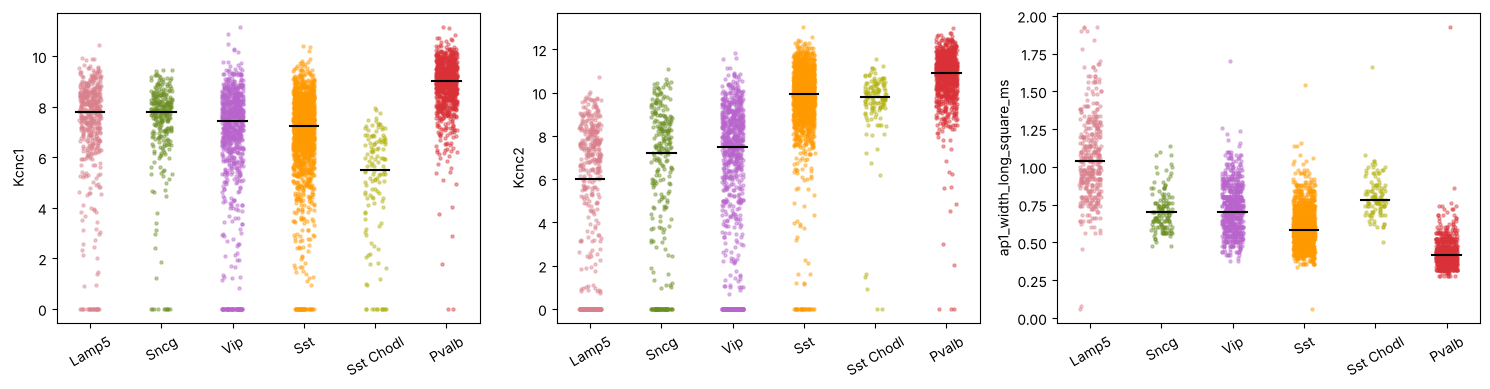

In [22]:
mouse_ephys = pd.read_csv(DATA / "mouse_ephys_features.csv")
both = (expr.reset_index()                                   # cell_id becomes a column again
        .merge(mouse_ephys, on="cell_id")
        .merge(cells[["cell_id", "subclass"]], on="cell_id"))
print(len(both), "cells with transcriptome and electrophysiology")


def strip_plot(df, feature, group, order, ax):
    """One column of dots per group, with the median as a black line (from last week)."""
    rng = np.random.default_rng(0)
    for k, g in enumerate(order):
        values = df.loc[df[group] == g, feature].dropna()
        x = k + rng.uniform(-0.15, 0.15, len(values))
        ax.scatter(x, values, s=5, color=COLORS[g], alpha=0.4)
        ax.plot([k - 0.2, k + 0.2], [values.median()] * 2, color="black")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=30)
    ax.set_ylabel(feature)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
strip_plot(both, "Kcnc1", "subclass", subclasses, axes[0])
strip_plot(both, "Kcnc2", "subclass", subclasses, axes[1])
strip_plot(both, "ap1_width_long_square_ms", "subclass", subclasses, axes[2])
plt.tight_layout()
plt.show()

And cell by cell: do cells with more *Kcnc2* have narrower spikes?

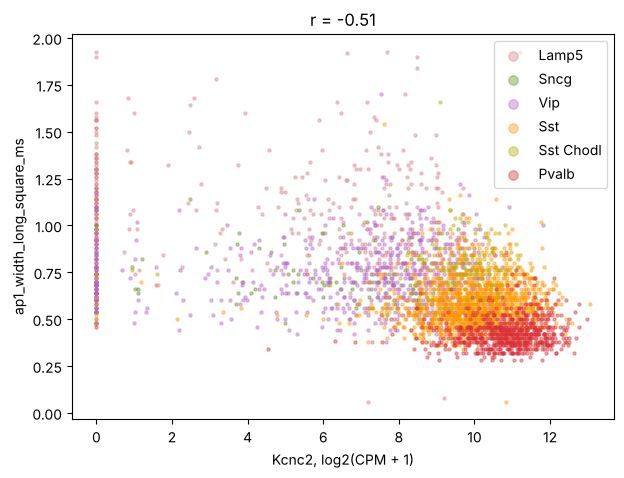

In [23]:
gene, feature = "Kcnc2", "ap1_width_long_square_ms"

fig, ax = plt.subplots(figsize=(7, 5))
for sc in subclasses:
    part = both[both["subclass"] == sc]
    ax.scatter(part[gene], part[feature], s=5, alpha=0.4, color=COLORS[sc], label=sc)
r = both[gene].corr(both[feature], method="spearman")
ax.set_title(f"r = {r:.2f}")
ax.set_xlabel(f"{gene}, log2(CPM + 1)")
ax.set_ylabel(feature)
ax.legend(markerscale=3)
plt.show()

### 5.1 Screening all channel genes

*Kcnc2* was our guess. But we have 144 channel genes: we can simply compute the correlation of **each** of them with
the spike width, and let the data tell us which ones matter. `corrwith` correlates every column of a table with one
other column.

In [24]:
r_width = both[channel_genes].corrwith(both["ap1_width_long_square_ms"], method="spearman")
r_width = r_width.dropna().sort_values()

family = genes.set_index("mouse_symbol")["family"]
top = pd.DataFrame({"r": r_width.round(2), "family": family[r_width.index]})
top.head(8)

,r,family
Kcnc2,-0.51,Voltage-gated potassium channels (Kv)
Kcnma1,-0.42,Calcium- and sodium-activated potassium channe...
Kcna1,-0.40,Voltage-gated potassium channels (Kv)
Kcnc1,-0.40,Voltage-gated potassium channels (Kv)
Kcnq3,-0.38,Voltage-gated potassium channels (Kv)
Scn1a,-0.35,Voltage-gated sodium channels (NaV)
Kcnk3,-0.35,Two-pore domain potassium channels (K2P)
Kcnc3,-0.34,Voltage-gated potassium channels (Kv)


In [25]:
top.tail(5)

,r,family
Kcnk9,0.33,Two-pore domain potassium channels (K2P)
Kcnn2,0.37,Calcium- and sodium-activated potassium channe...
Trpc5,0.40,Transient Receptor Potential channels (TRP)
Kcnt2,0.43,Calcium- and sodium-activated potassium channe...
Kcnd3,0.46,Voltage-gated potassium channels (Kv)


**Questions.**
* Which channel families come up at the top (more expression, narrower spikes)? Does that fit what you know about how
  an action potential ends? (*Kcnma1* is the BK channel, a Ca²⁺-activated K⁺ channel.)
* Change the feature: which genes go with the input resistance? With the sag (*Hcn* genes code the *I*<sub>h</sub>
  current)? Are the correlations as strong?

Just as with size and input resistance last week, we should ask: is this only because Pvalb cells have both more
*Kcnc2* and narrower spikes? What happens **within** each subclass?

In [26]:
def spearman(df):
    return df[gene].corr(df[feature], method="spearman")

both.groupby("subclass")[[gene, feature]].apply(spearman).loc[subclasses].round(2)

subclass
Lamp5       -0.29
Sncg        -0.25
Vip          0.07
Sst          0.09
Sst Chodl    0.02
Pvalb        0.11
dtype: float64

**Questions to think about.**
* Within a subclass the relation is much weaker. Name a few reasons why the RNA of one gene in one cell cannot predict
  that cell's spike width precisely. (Think of dropouts, of mRNA versus protein, of where in the cell the channels sit,
  and of the many other channels involved.)
* So what *do* these correlations tell us?

## 6. Mouse and human

The human cells have their own expression table, with the same 184 genes, in human symbols. `genes_selected.csv`
pairs each mouse gene with its human counterpart (its **ortholog**). The two datasets come from different
laboratories' pipelines, so we compare *patterns*, not absolute values: for each subclass, which genes are higher and
which are lower **than in the other subclasses** of the same species.

In [27]:
human_expr = pd.read_parquet(DATA / "human_expression_selected.parquet")
print(human_expr.shape)

pairs = genes[genes["in_mouse_data"] & genes["in_human_data"]]
harmonized = ["Lamp5/Pax6/Other", "Vip", "Sst", "Pvalb"]

# average profile of each subclass, genes as rows, human gene names for both species
mouse_group = cells_by_id.loc[expr.index, "subclass_harmonized"]
mouse_mean = expr[pairs["mouse_symbol"]].groupby(mouse_group).mean().loc[harmonized]
mouse_mean.columns = pairs["human_symbol"]

human_group = cells_by_id.loc[human_expr.index, "subclass_harmonized"]
human_mean = human_expr[pairs["human_symbol"]].groupby(human_group).mean().loc[harmonized]

# what is special about each subclass: subtract each gene's average over the four subclasses (within each species)
mouse_mean = mouse_mean - mouse_mean.mean()
human_mean = human_mean - human_mean.mean()

profiles = pd.concat([mouse_mean.T.add_prefix("mouse "), human_mean.T.add_prefix("human ")], axis=1)
profiles.head()

(778, 185)


subclass_harmonized,mouse Lamp5/Pax6/Other,mouse Vip,mouse Sst,mouse Pvalb,human Lamp5/Pax6/Other,human Vip,human Sst,human Pvalb
CACNA1S,-0.021245,0.095932,-0.022226,-0.052460,0.221764,-0.194723,0.073665,-0.100706
CACNA1C,0.079195,-0.370421,0.598319,-0.307094,-0.968792,0.284658,0.367085,0.317048
CACNA1D,0.049267,-0.166484,-0.368865,0.486083,-0.856873,0.955791,-0.332115,0.233197
CACNA1F,0.034300,-0.021398,-0.016760,0.003858,0.041264,-0.227600,0.154284,0.032053
CACNA1A,-1.527834,-0.788371,0.968755,1.347447,-0.395368,-1.362716,0.808432,0.949653


Now every column is the gene profile of one subclass in one species: positive for the genes it uses more than the
other subclasses, negative for the ones it uses less. Correlating the columns tells us how similar two profiles are
(1: the same genes are up and down, 0: unrelated, −1: opposite).

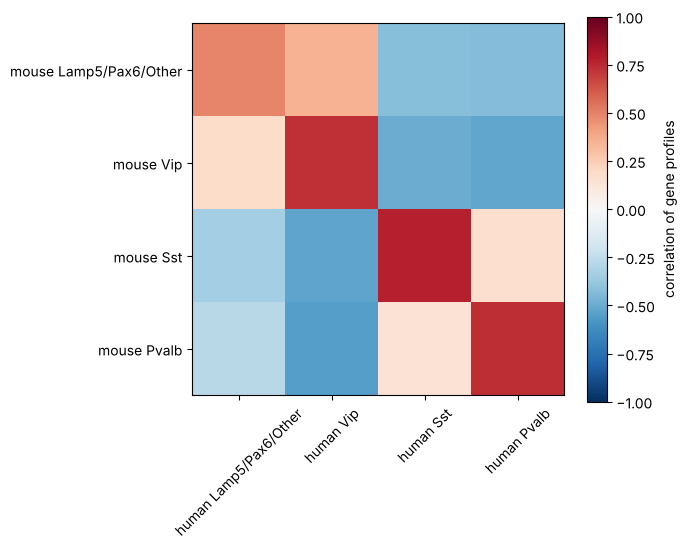

subclass_harmonized,human Lamp5/Pax6/Other,human Vip,human Sst,human Pvalb
subclass_harmonized,,,,
mouse Lamp5/Pax6/Other,0.49,0.35,-0.43,-0.43
mouse Vip,0.18,0.73,-0.49,-0.52
mouse Sst,-0.34,-0.53,0.78,0.17
mouse Pvalb,-0.28,-0.55,0.14,0.74


In [28]:
similarity = profiles.corr().loc[["mouse " + s for s in harmonized], ["human " + s for s in harmonized]]

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(similarity, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels(similarity.columns, rotation=45)
ax.set_yticks(range(4))
ax.set_yticklabels(similarity.index)
fig.colorbar(image, label="correlation of gene profiles")
plt.show()
similarity.round(2)

**Questions.**
* Which human subclass is most similar to mouse Pvalb cells? To mouse Vip cells? What does that tell you about these
  cell types across 80 million years of evolution?
* Does the Kv3 story hold in human, too? The human spike width is `width_rheobase_s` (in seconds) in
  `human_ephys_features.csv`. Repeat the screen of section 5.1 with the human data.

## Summary

* A transcriptome is a list of read counts, one per gene; for thousands of cells it is a sparse cells × genes matrix,
  stored with its cell and gene tables in an AnnData file.
* Counts depend on how deeply a cell was sequenced; dividing by the library size (CPM) and taking log2(CPM + 1) makes
  cells comparable.
* A handful of marker genes identifies the subclasses, and PCA finds the same groups without being told; single cells
  are noisy (dropouts, contamination).
* Ion channel genes differ between subclasses in the way their firing does: Pvalb cells express more Kv3 (*Kcnc*)
  channels and have narrower spikes. Within a subclass, single genes predict little.
* The gene profiles of the subclasses are conserved between mouse and human.

**Next: projects.** You now know all three modalities of Patch-seq: shape, firing and genes, for the same cells.